### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*



In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import kagglehub
import matplotlib.pyplot as plt
from kagglehub import KaggleDatasetAdapter



In [3]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
df.head(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
cat_bestseller = pd.crosstab(df["category"], df["isBestSeller"])

cat_bestseller.head()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3


In [ ]:
cat_bestseller["bestseller_ratio"] = (
    cat_bestseller[True] / (cat_bestseller[True] + cat_bestseller[False]))
bestseller_ratio_sorted = cat_bestseller.sort_values(by="bestseller_ratio",ascending=False)

bestseller_ratio_sorted.head(10)

isBestSeller,False,True,bestseller_ratio
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
"Billiard, Snooker & Pool",241,8,0.032129
Pet Supplies,9152,285,0.030200
Home Brewing & Wine Making,239,7,0.028455
Wind Instruments,243,7,0.028000



2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [12]:
from scipy.stats import chi2_contingency

cat_bestseller = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p, dof, expected = chi2_contingency(cat_bestseller)

print("Chi-square statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


In [13]:
n = cat_bestseller.to_numpy().sum()
min_dim = min(cat_bestseller.shape) - 1

cramers_v = np.sqrt(chi2 / (n * min_dim))

print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

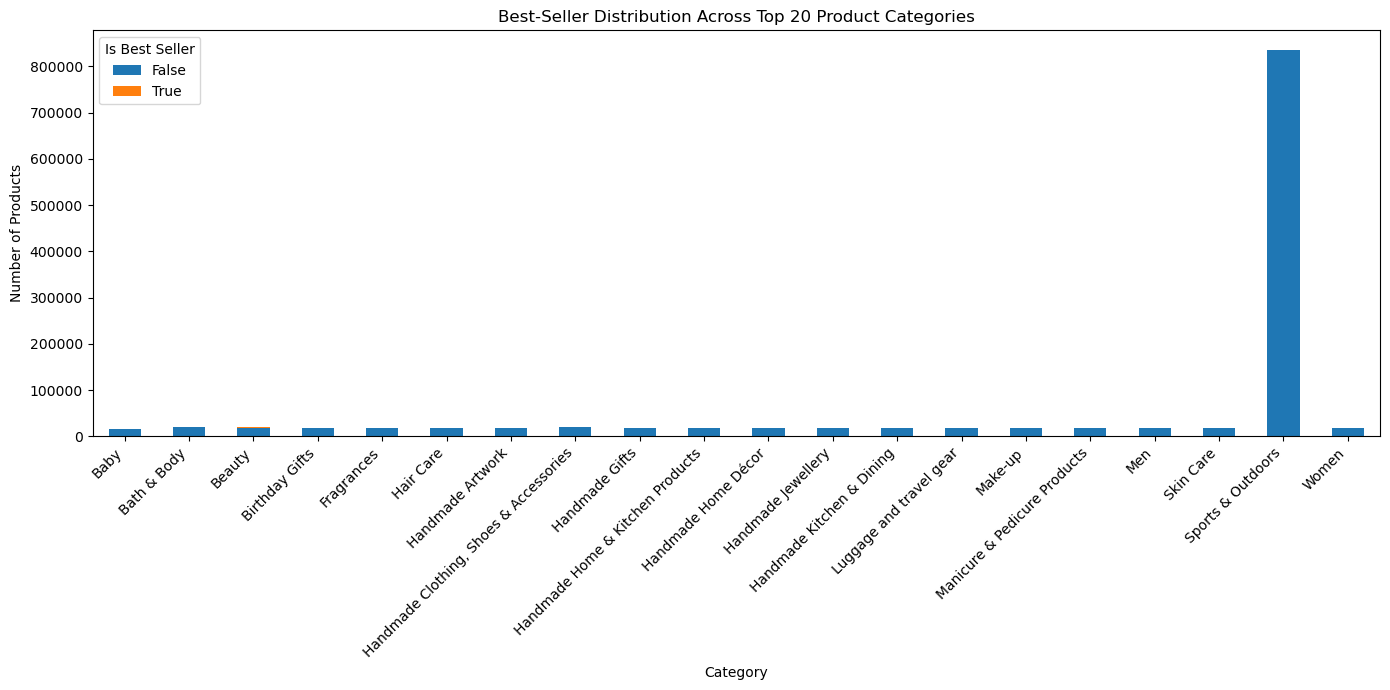

In [17]:
top_20_categories = df["category"].value_counts().head(20).index

filtered_df = df[df["category"].isin(top_20_categories)]

stacked_data = pd.crosstab(filtered_df["category"],filtered_df["isBestSeller"])

stacked_data.plot(kind="bar",stacked=True,figsize=(14, 7))

plt.title("Best-Seller Distribution Across Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Is Best Seller")
plt.tight_layout()
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*


In [18]:

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Lower bound: -44.01
Upper bound: 99.99000000000001


In [20]:
df_no_outliers = df[(df["price"] >= lower_bound) &(df["price"] <= upper_bound)]

print("Original rows:", len(df))
print("Rows after removing outliers:", len(df_no_outliers))
print("Rows removed:", len(df) - len(df_no_outliers))

Original rows: 2443651
Rows after removing outliers: 2115963
Rows removed: 327688


1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.
    

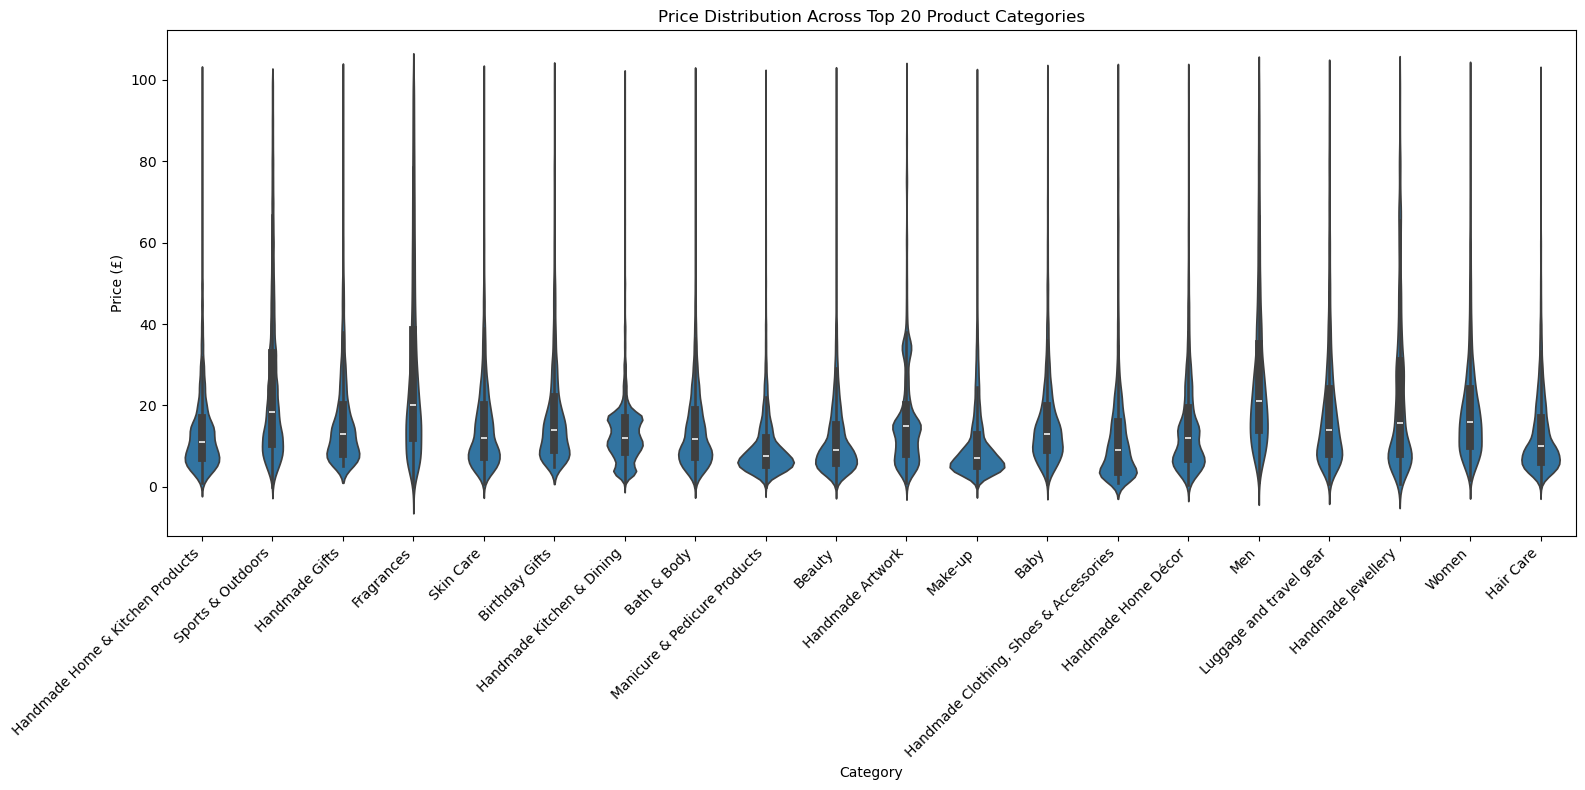

In [21]:

top_20_categories = (df_no_outliers["category"].value_counts().head(20).index)

filtered_df = df_no_outliers[ df_no_outliers["category"].isin(top_20_categories)]

plt.figure(figsize=(16, 8))
sns.violinplot(data=filtered_df,x="category",y="price")

plt.title("Price Distribution Across Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [22]:
median_prices=df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False)
print(median_prices.head(10))

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64


2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

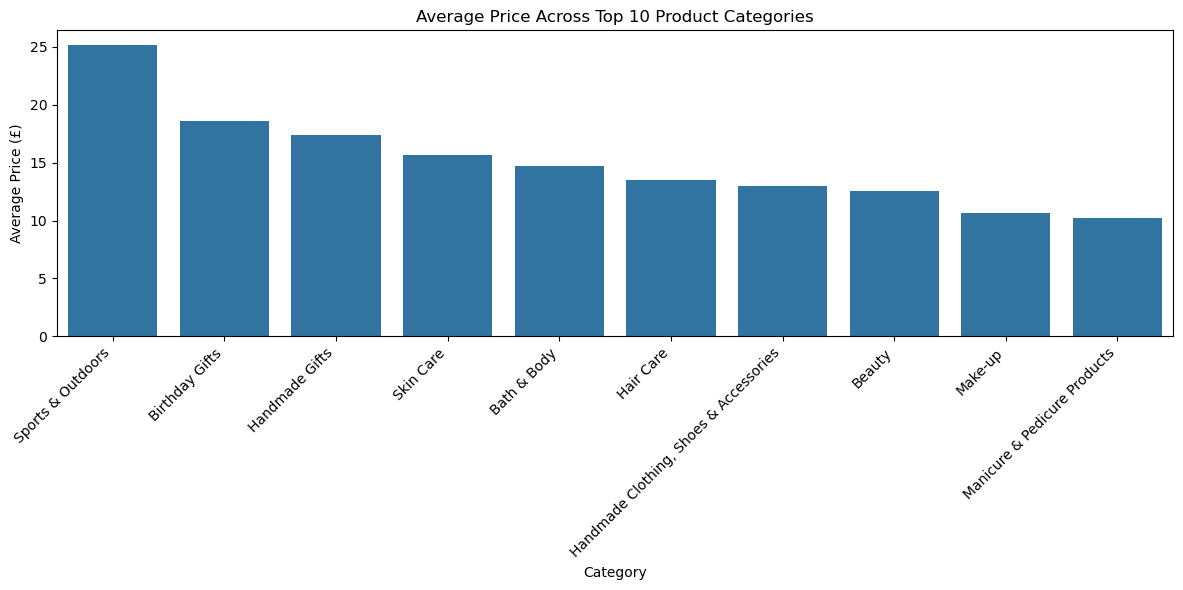

In [24]:
top_10_categories=df_no_outliers["category"].value_counts().head(10).index
avg_prices=df_no_outliers[df_no_outliers["category"].isin(top_10_categories)].groupby("category")["price"].mean().sort_values(ascending=False)

plt.figure(figsize=(12,6))
sns.barplot(x=avg_prices.index,y=avg_prices.values)
plt.title("Average Price Across Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [25]:
avg_price_all=df_no_outliers.groupby("category")["price"].mean().sort_values(ascending=False)
print(avg_price_all.head(10))

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


 **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

---

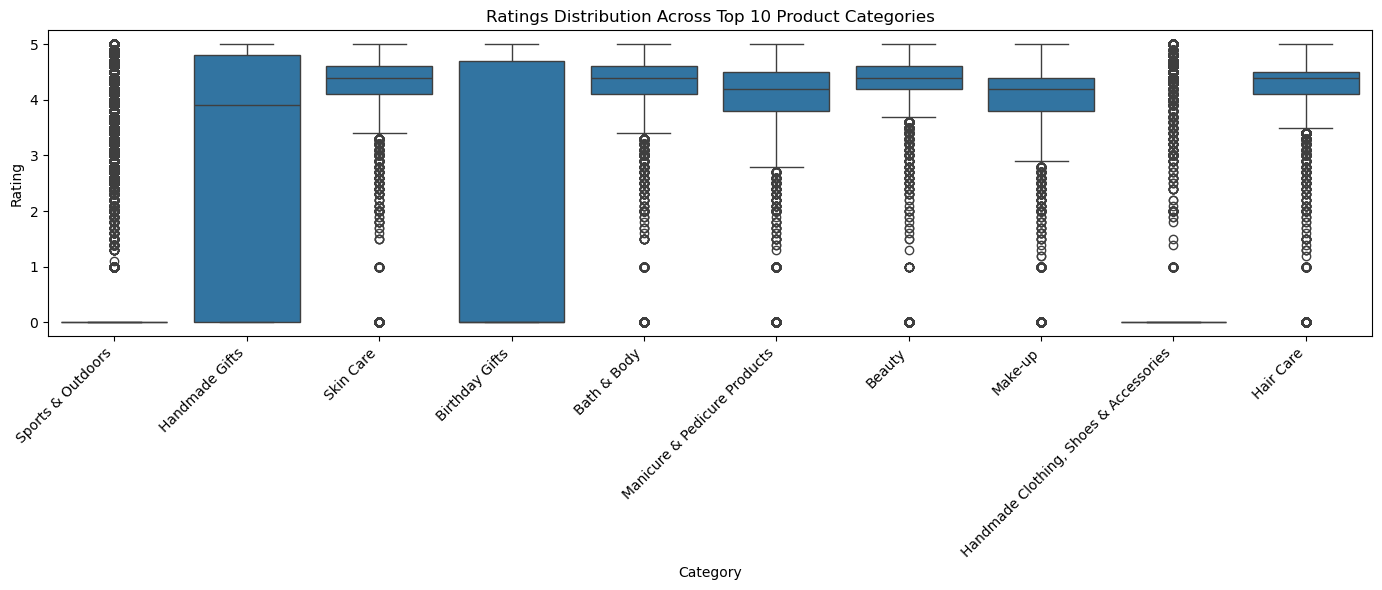

In [26]:
top_10_categories=df_no_outliers["category"].value_counts().head(10).index
filtered_df=df_no_outliers[df_no_outliers["category"].isin(top_10_categories)]

plt.figure(figsize=(14,6))
sns.boxplot(data=filtered_df,x="category",y="stars")
plt.title("Ratings Distribution Across Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.xticks(rotation=45,ha="right")
plt.tight_layout()
plt.show()

In [27]:
median_ratings=df_no_outliers.groupby("category")["stars"].median().sort_values(ascending=False)
print(median_ratings.head(10))

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Hobbies                         4.6
Beer, Wine & Spirits            4.6
Laptop Accessories              4.6
Cables & Accessories            4.5
CPUs                            4.5
Name: stars, dtype: float64


### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
	

In [28]:
correlation=df_no_outliers["price"].corr(df_no_outliers["stars"])
print("Correlation between price and stars:",correlation)

Correlation between price and stars: -0.07767299878178476


In [29]:
correlation=df_no_outliers["stars"].corr(df_no_outliers["price"])
print("Correlation between stars and price:",correlation)

Correlation between stars and price: -0.07767299878178476


	
2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 


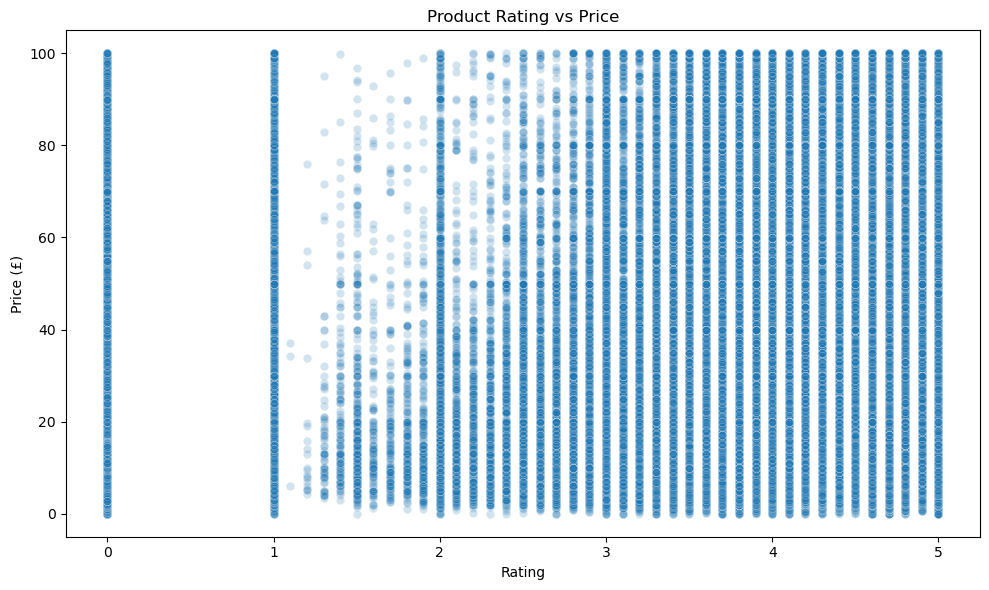

In [30]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_no_outliers,x="stars",y="price",alpha=0.2)
plt.title("Product Rating vs Price")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.tight_layout()
plt.show()

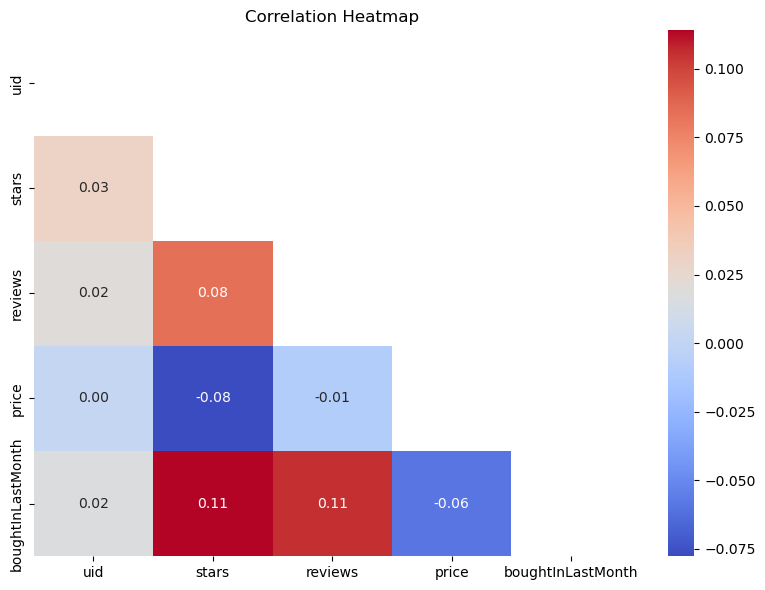

In [32]:
numeric_df=df_no_outliers.select_dtypes(include=["number"])
corr_matrix=numeric_df.corr()
mask=np.triu(np.ones_like(corr_matrix,dtype=bool))

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix,mask=mask,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

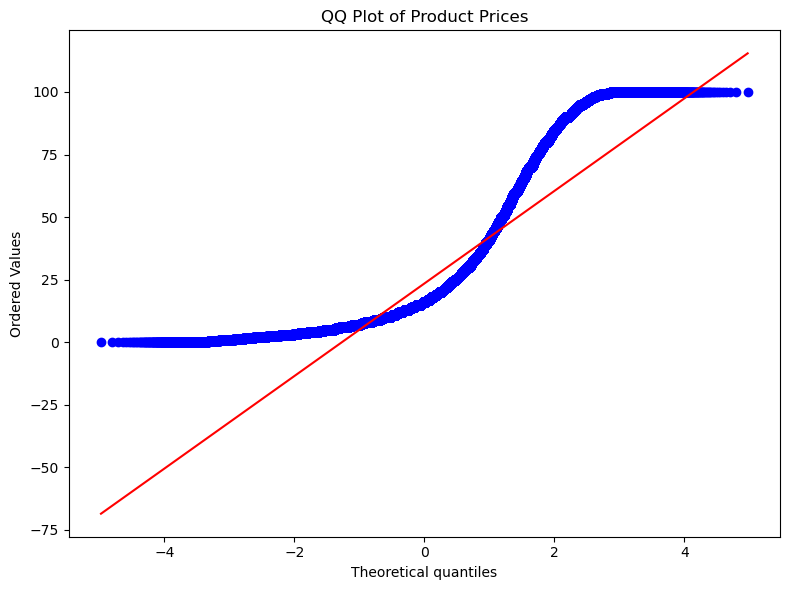

In [33]:
import scipy.stats as stats

plt.figure(figsize=(8,6))
stats.probplot(df_no_outliers["price"],dist="norm",plot=plt)
plt.title("QQ Plot of Product Prices")
plt.tight_layout()
plt.show()